# Simulasi Skenario Bahaya Luapan Kali Jagir dan Evakuasi Interaktif

Computer Graphics, AFL 2. Area studi: sekitar Pintu Air Jagir, Kecamatan Wonokromo, Surabaya.

Alur notebook:
1. Memuat 4 layer spasial dan mengubah CRS ke meter
2. Operasi GIS 1: buffer zona bahaya dari tepi Kali Jagir
3. Operasi GIS 2: spatial join bangunan dan shelter dengan zona bahaya
4. Operasi GIS 3: point-in-polygon untuk posisi warga (dipindah dengan matriks translasi)
5. Operasi GIS 4: rute terpendek ke shelter aman lewat jalan yang tidak tergenang
6. Peta, kontrol interaktif, dan animasi GIF

Zona bahaya adalah **skenario penyaringan awal**, bukan prediksi banjir: elevasi tanah, tanggul, dan drainase tidak dihitung.

In [1]:
import geopandas as gpd
import ipywidgets as widgets
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import LineString, Point, box

## Konstanta

- `CRS_DEGREE` = EPSG:4326, koordinat asli OpenStreetMap (derajat).
- `CRS_METER` = EPSG:32749 (UTM zona 49S), dipakai untuk semua perhitungan jarak dan luas.
- Radius 15 m = garis sempadan minimum sungai tidak bertanggul di kawasan perkotaan dengan kedalaman 3–20 m (Permen PUPR 28/2015 Pasal 5 ayat 1b). 100 m dan 200 m adalah skenario hipotetis.

In [2]:
DATA_DIR = "data"
CRS_DEGREE = "EPSG:4326"
CRS_METER = "EPSG:32749"

STUDY_AREA = (112.728, -7.312, 112.760, -7.292)  # (west, south, east, north) in degrees
SCENARIOS_M = [15, 100, 200]
RESIDENT_START = (112.75026, -7.30208)            # road junction ~80 m north of Kali Jagir
STEP_M = 25                                       # one button press moves the resident 25 m
EXIT_RADIUS_M = 300                               # how far the resident may wade to reach a dry road

COLORS = {
    "zone": "#e74c3c",
    "water": "#2e86c1",
    "building": "#d5d8dc",
    "building_hit": "#c0392b",
    "road": "#aab7b8",
    "shelter_safe": "#27ae60",
    "shelter_flooded": "#7b241c",
    "resident": "#8e44ad",
    "route": "#f1c40f",
}

## 1. Memuat layer spasial

Setiap layer dibaca dari file lokal (hasil `fetch_data.py`), diubah ke meter dengan `to_crs`, lalu dipotong ke area studi.
`to_crs` menghitung ulang koordinat; `set_crs` hanya memberi label dan tidak dipakai di sini.

In [3]:
study_area = gpd.GeoSeries([box(*STUDY_AREA)], crs=CRS_DEGREE).to_crs(CRS_METER).iloc[0]


def load_layer(name):
    gdf = gpd.read_file(f"{DATA_DIR}/{name}.geojson")
    return gdf.to_crs(CRS_METER).clip(study_area)


rivers = load_layer("sungai")
water = load_layer("badan_air")
buildings = load_layer("bangunan")
shelters = load_layer("shelter")

buildings = buildings[buildings.geom_type.isin(["Polygon", "MultiPolygon"])]
shelters["geometry"] = shelters.geometry.centroid  # schools/mosques can be outlines; use one point each
jagir_water = water[water["name"] == "Kali Jagir"]

graph = ox.project_graph(ox.load_graphml(f"{DATA_DIR}/jalan_walk.graphml"), to_crs=CRS_METER)
roads = ox.graph_to_gdfs(graph, nodes=False)

### Validasi data (checklist Week 6)

Sebelum analisis: CRS benar, tidak ada geometri kosong/tidak valid, dan ID unik.

In [4]:
layers = {"sungai": rivers, "badan air": water, "bangunan": buildings, "shelter": shelters, "jalan": roads}

for name, gdf in layers.items():
    print(f"{name:10s} {len(gdf):6d} fitur | EPSG:{gdf.crs.to_epsg()} | "
          f"tidak valid: {(~gdf.is_valid).sum()} | kosong: {gdf.is_empty.sum()}")

assert shelters["id"].is_unique and buildings["id"].is_unique
assert not jagir_water.empty, "Kali Jagir water polygon not found"
print("\nShelter per jenis:", shelters["amenity"].value_counts().to_dict())

sungai          8 fitur | EPSG:32749 | tidak valid: 0 | kosong: 0
badan air      35 fitur | EPSG:32749 | tidak valid: 0 | kosong: 0
bangunan    36259 fitur | EPSG:32749 | tidak valid: 0 | kosong: 0
shelter       115 fitur | EPSG:32749 | tidak valid: 0 | kosong: 0
jalan        5386 fitur | EPSG:32749 | tidak valid: 0 | kosong: 0

Shelter per jenis: {'place_of_worship': 55, 'school': 49, 'university': 6, 'college': 4, 'community_centre': 1}


## 2. Operasi GIS 1: buffer zona bahaya

`buffer(r)` membuat poligon berisi semua titik yang jaraknya ≤ r meter dari tepi badan air Kali Jagir.
`union_all()` menggabungkan potongan buffer menjadi satu poligon sehingga setiap bangunan hanya dihitung sekali,
lalu zona dipotong ke area studi.

In [5]:
def flood_zone(radius_m):
    return jagir_water.buffer(radius_m).union_all().intersection(study_area)

## 3. Operasi GIS 2: spatial join (predikat `intersects`)

Bangunan atau shelter yang berada di dalam **atau menyentuh** batas zona ditandai terdampak (aturan inklusi batas, Week 6).

In [6]:
def affected(gdf, zone):
    zone_gdf = gpd.GeoDataFrame(geometry=[zone], crs=CRS_METER)
    joined = gpd.sjoin(gdf, zone_gdf, how="left", predicate="intersects")
    return joined["index_right"].notna().to_numpy()


rows = []
for radius in SCENARIOS_M:
    zone = flood_zone(radius)
    hit = affected(buildings, zone)
    flooded = affected(shelters, zone)
    rows.append({
        "radius (m)": radius,
        "bangunan terdampak": int(hit.sum()),
        "luas tapak terdampak (m²)": round(buildings[hit].area.sum()),
        "shelter tergenang": int(flooded.sum()),
        "shelter aman": int((~flooded).sum()),
    })

summary = pd.DataFrame(rows)
summary

,radius (m),bangunan terdampak,luas tapak terdampak (m²),shelter tergenang,shelter aman
0,15,244,11360,0,115
1,100,1793,128762,6,109
2,200,3731,287393,10,105


## 4. Operasi GIS 3: posisi warga dan point-in-polygon

Warga dipindah dengan **matriks translasi koordinat homogen** dalam bentuk vektor baris, sama seperti materi Week 3:

$$[x' \; y' \; 1] = [x \; y \; 1] \begin{bmatrix} 1 & 0 & 0 \\ 0 & 1 & 0 \\ t_x & t_y & 1 \end{bmatrix}$$

Setelah pindah, `within` mengecek apakah warga berada di dalam zona bahaya.

In [7]:
def translate(point, tx, ty):
    T = np.array([[1, 0, 0],
                  [0, 1, 0],
                  [tx, ty, 1]])
    x, y, _ = np.array([point.x, point.y, 1]) @ T
    return Point(x, y)


def resident_status(point, zone):
    return "BAHAYA" if point.within(zone) else "AMAN"


resident_start = gpd.GeoSeries([Point(RESIDENT_START)], crs=CRS_DEGREE).to_crs(CRS_METER).iloc[0]

moved = translate(resident_start, 30, 20)
print(f"start ({resident_start.x:.0f}, {resident_start.y:.0f}) -> after T(30, 20): ({moved.x:.0f}, {moved.y:.0f})")
for radius in SCENARIOS_M:
    print(f"radius {radius:3d} m: warga {resident_status(resident_start, flood_zone(radius))}")

start (693220, 9192482) -> after T(30, 20): (693250, 9192502)
radius  15 m: warga AMAN
radius 100 m: warga BAHAYA
radius 200 m: warga BAHAYA


## 5. Operasi GIS 4: rute terpendek lewat jalan kering

1. Ruas jalan yang berpotongan dengan zona bahaya dihapus dari graf.
2. Warga mungkin sedang berdiri di genangan, jadi warga dihubungkan dengan garis lurus ke setiap simpul jalan kering
   dalam radius 300 m, kecuali garis yang menyeberangi sungai. Tiap shelter aman memakai simpul terdekatnya (`nearest_nodes`).
3. Dijkstra (`single_source_dijkstra`, bobot = panjang dalam meter) mencari shelter dengan jarak tempuh terpendek.
4. Jika tidak ada shelter yang bisa dicapai, fungsi mengembalikan `None` dan notebook menampilkan pesan.

In [8]:
def dry_graph(zone):
    flooded_edges = roads[roads.intersects(zone)].index  # (u, v, key) of each flooded road segment
    g = graph.copy()
    g.remove_edges_from(flooded_edges)
    g.remove_nodes_from(list(nx.isolates(g)))
    return g


river_area = water.union_all()


def connect_resident(g, resident):
    nodes = ox.graph_to_gdfs(g, edges=False)
    exits = nodes[nodes.distance(resident) <= EXIT_RADIUS_M]
    g.add_node("warga", x=resident.x, y=resident.y)
    for node, row in exits.iterrows():
        if not LineString([resident, row.geometry]).intersects(river_area):
            g.add_edge("warga", node, length=resident.distance(row.geometry))


def evacuation_route(resident, zone):
    safe = shelters[~affected(shelters, zone)]
    g = dry_graph(zone)
    if safe.empty or g.number_of_nodes() == 0:
        return None

    targets = ox.distance.nearest_nodes(g, safe.geometry.x, safe.geometry.y)
    connect_resident(g, resident)
    distance, paths = nx.single_source_dijkstra(g, "warga", weight="length")

    reachable = [(distance[node], i) for i, node in enumerate(targets) if node in distance]
    if not reachable:
        return None

    best_distance, best = min(reachable)
    shelter = safe.iloc[best]
    path = [(g.nodes[n]["x"], g.nodes[n]["y"]) for n in paths[targets[best]]]
    line = LineString([*path, (shelter.geometry.x, shelter.geometry.y)])
    return {"shelter": shelter["name"], "distance_m": best_distance, "line": line}


for radius in SCENARIOS_M:
    route = evacuation_route(resident_start, flood_zone(radius))
    if route is None:
        print(f"radius {radius:3d} m: tidak ada rute kering")
    else:
        print(f"radius {radius:3d} m: ke {route['shelter']} ({route['distance_m']:.0f} m lewat jalan)")

radius  15 m: ke Masjid Nurul Islam (94 m lewat jalan)
radius 100 m: ke Gereja Kalam Hidup (429 m lewat jalan)
radius 200 m: ke Gereja Kalam Hidup (510 m lewat jalan)


## 6. Peta

Urutan gambar: zona bahaya (transparan) → sungai → bangunan → jalan dan rute → shelter → warga → label dan legenda.

In [9]:
LEGEND = [
    Patch(color=COLORS["zone"], alpha=0.3, label="Zona bahaya"),
    Patch(color=COLORS["water"], label="Kali Jagir / sungai"),
    Patch(color=COLORS["building_hit"], label="Bangunan terdampak"),
    Line2D([], [], color=COLORS["route"], linewidth=3, label="Rute evakuasi"),
    Line2D([], [], marker="s", color=COLORS["shelter_safe"], linestyle="", label="Shelter aman"),
    Line2D([], [], marker="X", color=COLORS["shelter_flooded"], linestyle="", label="Shelter tergenang"),
    Line2D([], [], marker="o", color=COLORS["resident"], linestyle="", label="Warga"),
]


def clip_layers(area):
    return {
        "water": water.clip(area),
        "buildings": buildings.clip(area),
        "roads": roads.clip(area),
        "shelters": shelters.clip(area),
    }


def draw_map(ax, layers, zone, resident=None, route=None, title=""):
    hit = affected(layers["buildings"], zone)
    flooded = affected(layers["shelters"], zone)
    shelter_names = layers["shelters"]["name"].fillna("")

    gpd.GeoSeries([zone], crs=CRS_METER).plot(ax=ax, color=COLORS["zone"], alpha=0.3, zorder=1)
    layers["water"].plot(ax=ax, color=COLORS["water"], zorder=2)
    layers["buildings"][~hit].plot(ax=ax, color=COLORS["building"], zorder=3)
    if hit.any():
        layers["buildings"][hit].plot(ax=ax, color=COLORS["building_hit"], zorder=3)
    layers["roads"].plot(ax=ax, color=COLORS["road"], linewidth=0.6, zorder=4)
    if route is not None:
        gpd.GeoSeries([route["line"]]).plot(ax=ax, color=COLORS["route"], linewidth=3, zorder=5)
    layers["shelters"][~flooded].plot(ax=ax, color=COLORS["shelter_safe"], marker="s", markersize=40, zorder=6)
    if flooded.any():
        layers["shelters"][flooded].plot(ax=ax, color=COLORS["shelter_flooded"], marker="X", markersize=50, zorder=6)
    if resident is not None:
        ax.scatter(resident.x, resident.y, s=140, color=COLORS["resident"], edgecolor="white", zorder=7)
    if route is not None:
        end = route["line"].coords[-1]
        ax.annotate(route["shelter"], end, xytext=(6, 6), textcoords="offset points", fontsize=8,
                    weight="bold", zorder=8)

    ax.set_title(title, fontsize=11)
    ax.legend(handles=LEGEND, loc="lower left", fontsize=7, framealpha=0.9)
    ax.set_axis_off()

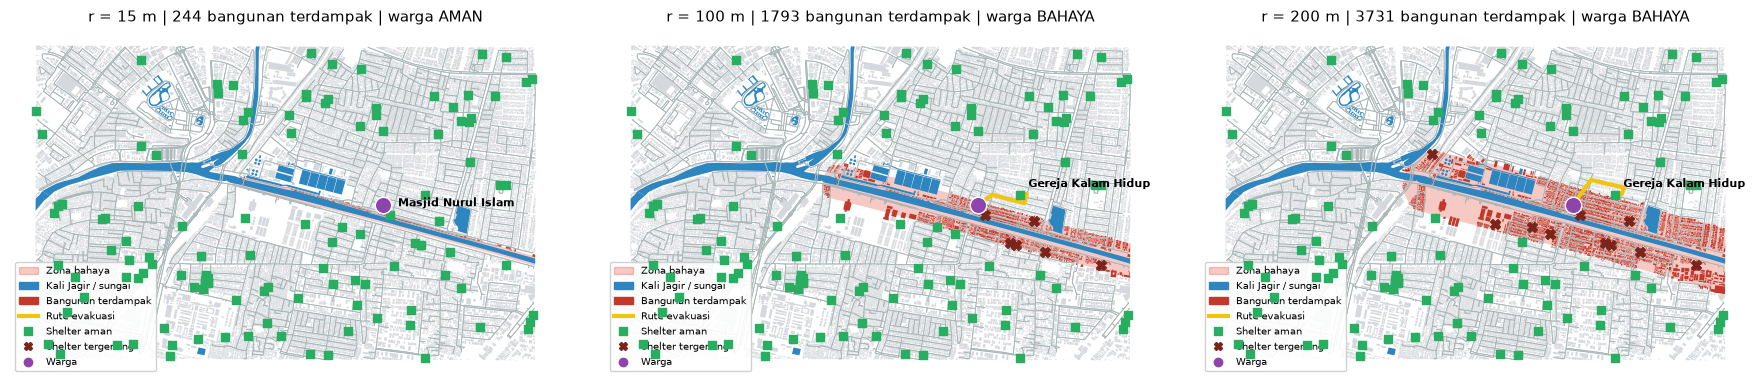

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
full = clip_layers(study_area)

for ax, radius in zip(axes, SCENARIOS_M):
    zone = flood_zone(radius)
    route = evacuation_route(resident_start, zone)
    row = summary[summary["radius (m)"] == radius].iloc[0]
    title = (f"r = {radius} m | {row['bangunan terdampak']} bangunan terdampak | "
             f"warga {resident_status(resident_start, zone)}")
    draw_map(ax, full, zone, resident_start, route, title)

plt.tight_layout()
fig.savefig("output/peta_skenario.png", dpi=150)
plt.show()

## 7. Kontrol interaktif

Geser slider untuk mengubah radius luapan, tekan tombol arah untuk memindahkan warga 25 m (pakai `translate`).
Peta hanya menampilkan jendela 1,6 km × 1 km di sekitar warga agar cepat digambar.

In [11]:
view = box(resident_start.x - 800, resident_start.y - 500, resident_start.x + 800, resident_start.y + 500)
view_layers = clip_layers(view)
state = {"resident": resident_start}

radius_slider = widgets.IntSlider(value=15, min=15, max=200, step=5, description="Radius (m)")
moves = {"Utara": (0, STEP_M), "Selatan": (0, -STEP_M), "Barat": (-STEP_M, 0), "Timur": (STEP_M, 0)}
buttons = [widgets.Button(description=name) for name in moves]
output = widgets.Output()


def redraw(*_):
    zone = flood_zone(radius_slider.value)
    route = evacuation_route(state["resident"], zone)
    status = resident_status(state["resident"], zone)
    target = "tidak ada rute kering" if route is None else f"{route['shelter']} ({route['distance_m']:.0f} m)"
    with output:
        output.clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(10, 6.5))
        draw_map(ax, view_layers, zone, state["resident"], route,
                 f"r = {radius_slider.value} m | warga {status} | tujuan: {target}")
        ax.set_xlim(view.bounds[0], view.bounds[2])
        ax.set_ylim(view.bounds[1], view.bounds[3])
        plt.show()


def move(button):
    tx, ty = moves[button.description]
    state["resident"] = translate(state["resident"], tx, ty)
    redraw()


radius_slider.observe(redraw, names="value")
for button in buttons:
    button.on_click(move)

display(widgets.VBox([radius_slider, widgets.HBox(buttons), output]))
redraw()

## 8. Animasi GIF

- Fase 1: radius naik dari 15 m ke 200 m, bangunan dan shelter berubah warna.
- Fase 2: warga berjalan menyusuri rute. Posisi pada tiap ruas dihitung dengan kurva Bézier linear (Week 2):

$$p(t) = (1 - t)P_0 + tP_1, \quad 0 \le t \le 1$$

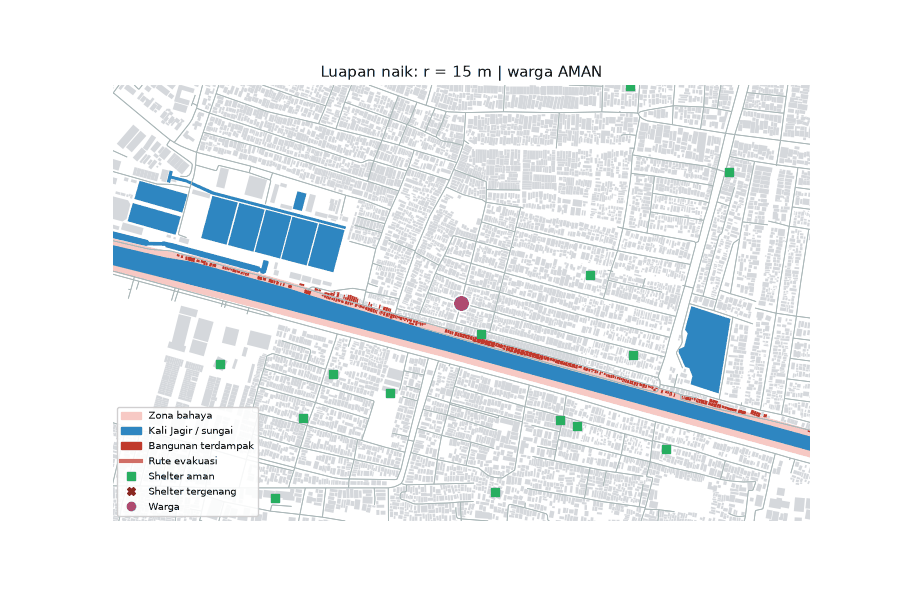

In [12]:
def walk_position(line, fraction):
    points = np.array(line.coords)
    lengths = np.hypot(*np.diff(points, axis=0).T)
    remaining = fraction * lengths.sum()
    for p0, p1, length in zip(points[:-1], points[1:], lengths):
        if remaining <= length:
            t = remaining / length if length > 0 else 0
            return Point((1 - t) * p0 + t * p1)
        remaining -= length
    return Point(points[-1])


FLOOD_FRAMES = 25
WALK_FRAMES = 30
radii = np.linspace(15, 200, FLOOD_FRAMES)
final_zone = flood_zone(200)
final_route = evacuation_route(resident_start, final_zone)

fig, ax = plt.subplots(figsize=(9, 6))


def draw_frame(i):
    ax.clear()
    if i < FLOOD_FRAMES:
        zone, resident, route = flood_zone(radii[i]), resident_start, None
        title = f"Luapan naik: r = {radii[i]:.0f} m | warga {resident_status(resident, zone)}"
    else:
        fraction = (i - FLOOD_FRAMES) / (WALK_FRAMES - 1)
        zone, route = final_zone, final_route
        resident = walk_position(route["line"], fraction)
        title = f"Evakuasi ke {route['shelter']} | warga {resident_status(resident, zone)}"
    draw_map(ax, view_layers, zone, resident, route, title)
    ax.set_xlim(view.bounds[0], view.bounds[2])
    ax.set_ylim(view.bounds[1], view.bounds[3])


frames = FLOOD_FRAMES + (WALK_FRAMES if final_route is not None else 0)
animation = FuncAnimation(fig, draw_frame, frames=frames)
animation.save("output/animasi_evakuasi.gif", writer=PillowWriter(fps=8))
plt.close(fig)
display(Image(filename="output/animasi_evakuasi.gif"))

## Batasan

- Zona bahaya berbasis jarak, tidak mengikuti elevasi, tanggul, atau drainase.
- Kelengkapan data bergantung pada OpenStreetMap; kapasitas shelter tidak tersedia.
- Jika warga berada di dalam zona, langkah pertamanya berupa garis lurus (menembus genangan) ke salah satu simpul jalan kering dalam radius 300 m, lalu mengikuti jalan.